Para activar/desactivar notacion cientifica

In [ ]:

pd.set_option('display.float_format', lambda x: '%.2f' % x)
#pd.reset_option('display.float_format')

: 

In [18]:
#import numpy as np
np.set_printoptions(suppress=True, precision=4) # suppress=True evita la notación científica
#np.set_printoptions(suppress=False)

# Eligiendo modelos con incertidumbre

> All models are wrong, but some are useful.

George Box

> If you torture the data long enough, it will confess.

Ronald Coase

Necesitamos ganar la competencia. Para lograr esto, necesitamos "construir" el mejor modelo posible. Lo que nos platea dos preguntas clave:
* ¿qué significa construir un modelo?
* Y, en segundo lugar, si tenemos dos modelos, ¿cómo determinamos cuál es el mejor?

Empecemos realizando una comparación entre el modelo por defecto  de **árboles de decisión** (no controla el crecimiento) y uno levemente parametrizado.

Levantemos el entorno e instalemos los paquetes que nos probablemente no dispongamos. Se usarán a lo largo de la clase.

In [1]:
#%pip install optuna

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree,  _tree
from sklearn.model_selection import train_test_split
from sklearn.model_selection import ShuffleSplit, StratifiedShuffleSplit

from joblib import Parallel, delayed

from time import time

import optuna
from optuna.visualization import plot_param_importances, plot_contour,  plot_slice, plot_optimization_history

c:\Users\carof\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Notará a continuación que trabajaremos como mes de entrenamiento **Marzo** y reservaremos **Mayo** solo para pruebas

In [2]:
#dataset_path = '/content/drive/MyDrive/DMEyF/2026/notebooks/data/'
#dataset_file = 'competencia_01.csv'
dataset_path = "/Users/carof/Downloads/DENICOLAY/"
dataset_file = 'competencia_01.csv'

ganancia_acierto = 1_072_500
costo_estimulo = 27_500

mes_train = 202103
mes_test = 202105

# agregue su semilla
semilla = 17

data = pd.read_csv(dataset_path + dataset_file)

In [11]:
X = data[data['foto_mes'] == mes_train]
y = X['clase_ternaria']
X = X.drop(columns=['clase_ternaria'])

Y necesitamos una función que nos ayude a calcular la ganancia.

El parámetro `prop`, esta para corregir la ganancia cuando no estemos trabajando con una población entera. Si estamos utilizando, por ejemplo una muestra del 70%, para normalizar la ganancia, ponermos el parámetro `prop=0.7`

@np.vectorize toma una función que originalmente está escrita para procesar valores individuales (escalares) y la transforma en una función que puede recibir y procesar arreglos o vectores de NumPy elemento por elemento de forma automática.

In [10]:
def ganancia(model, X, y, prop=1, threshold=0.025):
  #necesitamos una función que nos ayude a calcular la ganancia.
  #El parámetro `prop`, esta para corregir la ganancia cuando no estemos trabajando con una población entera. Si estamos utilizando, por ejemplo una muestra del 70%, para normalizar la ganancia, ponermos el parámetro `prop=0.7`

  class_index = np.where(model.classes_ == "BAJA+2")[0][0]
  y_hat = model.predict_proba(X)

  @np.vectorize
  def ganancia_row(predicted, actual, threshold=0.025):
    return  (predicted >= threshold) * (ganancia_acierto if actual == "BAJA+2" else -costo_estimulo)

  return ganancia_row(y_hat[:,class_index], y).sum() / prop


Mira a continuación el siguiente código.

* ¿Cuál cree que es el mejor modelo?
* ¿Cuáles son los problemas que ve?

Valores por defecto:
class sklearn.tree.DecisionTreeClassifier(*, criterion='gini', splitter='best', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None, random_state=None, max_leaf_nodes=None, min_impurity_decrease=0.0, class_weight=None, ccp_alpha=0.0, monotonic_cst=None)[source]
https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html 

In [19]:
model_base = DecisionTreeClassifier()
model_ale = DecisionTreeClassifier(criterion='gini',
                               min_samples_split=80,
                               max_depth=5)

model_base.fit(X,y)
model_ale.fit(X,y)

ganancia_base = ganancia(model_base, X, y)
ganancia_ale = ganancia(model_ale, X, y)
print(f"Ganancia de modelo Base: {ganancia_base:,.0f}")
print(f"Ganancia de modelo Ale:  {ganancia_ale:,.0f}")

Ganancia de modelo Base: 1,029,600,000
Ganancia de modelo Ale:  296,285,000


In [9]:
ganancia_base / ganancia_ale

np.float64(3.475032485613514)

In [10]:
ganancia_base / ganancia_acierto

np.float64(960.0)

El modelo por defecto parece generar unas tres veces más ganancia que el de ale, pero no tenemos manera de saber si no estamos sobreajustando. 
En terminos absolutos no parece una gran ganancia además, pero no tengo criterios para juzgar esto

* ¿Cómo se pueden solucionar?

Dado que lo que hicimos no pinta nada bien, pasemos a una de las herramientas que separa la ciencia de datos de la estadística tradicional

* ¿Por qué separamos en train/test?
* ¿Cómo funciona la estadística tradicional?
* ¿Son números aleatorios los que nos dan las computadoras?
* ¿Por qué usamos semillas?
* ¿Qué es una partición estratificada?
* ¿Es realmente necesario en nuestro caso una partición estratificada?



1- para probar como performa nuestro modelo en datos nuevos
2- en general se evalua sobre los mismos datos de entrenamiento, proveyendo de una medida de incertidumbre de los parametros, haciendo suposiciones más o menos razonables sobre su distribución teórica
3- no, son pseudoaleatorios -> SE QUE ES ASI PERO GOOGLEAR PARA ENTENDER PQ
4- para poder replicar nuestros resultados, justamente en virtud de que los numeros que dan las computadoras son pseudoaleatorios
5- una partición que garantiza igual proporción de nuestro target en train y test (equivalente a la de la muestra en su conjunto) -> CHEQUEAR
6- si tenemos datos suficientes y nuestra partición en train y test es aleatoria, no es necesaria

Veamos alguna de las formas de separar los conjuntos de datos para medir su calidad:

* **Train-Test Split**: Divide el conjunto de datos en dos partes: un conjunto de entrenamiento y otro de prueba. El conjunto de entrenamiento se utiliza para ajustar el modelo, y el conjunto de prueba para evaluar su rendimiento.

* **K-Fold Cross Validation**: Divide los datos en k subconjuntos o folds. El modelo se entrena k veces, cada vez utilizando k-1 subconjuntos como entrenamiento y el subconjunto restante como prueba. Esto se repite hasta que cada subconjunto se haya utilizado como conjunto de prueba una vez.

* **Shuffle Split** (aka Montecarlo Cross Validation): Genera múltiples particiones aleatorias de los datos en conjuntos de entrenamiento y prueba. A diferencia de K-Fold, no garantiza que todos los puntos de datos sean utilizados en alguna iteración.

En la cátedra preferimos usar está última, pero el alumno es libre de usar la que considera conveniente.

Armemos ahora nuevamente los modelos anteriores, pero utilizando estas particiones y midiendo ya no en **train**, sino en los múltiples conjunto de **test**

El operador ** desempaqueta un diccionario para pasar sus pares clave-valor como argumentos con nombre (keyword arguments) a una función o clase

In [18]:
sss = StratifiedShuffleSplit(n_splits=20,
                             test_size=0.3,
                             random_state=semilla)

# Función que paraleliza la construcción de árboles de decisión
def train_and_evaluate(train_index, test_index, params, X, y):
  m = DecisionTreeClassifier(**params)
  m.fit(X.iloc[train_index],y.iloc[train_index])
  # Note que con el parámetro prop se corrige la distorsión por sampleo de la
  # ganancia -> HABIA QUE PONERLE LA PROP DE LA POBLACION/ MUESTRA CON LA QUE ESTAMOS TRABAJANDO
  # -> COMO ACA ABAJO SE APLICA GANANCIA A TEST, PROP es 30% de la muestra
  ganancia_value = ganancia(m, X.iloc[test_index], y.iloc[test_index], prop=0.3)
  return m, ganancia_value

modelo_base_param = {"random_state": semilla}

modelo_ale_param = {"criterion": 'gini',
                     "random_state": semilla,
                     "min_samples_split": 80,
                     "max_depth": 5,
}

results_base = Parallel(n_jobs=-1)(
    delayed(train_and_evaluate)(train_index, test_index, modelo_base_param, X, y)
    for train_index, test_index in sss.split(X, y)
)

results_ale = Parallel(n_jobs=-1)(
    delayed(train_and_evaluate)(train_index, test_index, modelo_ale_param, X, y)
    for train_index, test_index in sss.split(X, y)
)


In [12]:
results_base

[(DecisionTreeClassifier(random_state=17), np.float64(29241666.666666668)),
 (DecisionTreeClassifier(random_state=17), np.float64(27408333.333333336)),
 (DecisionTreeClassifier(random_state=17), np.float64(37950000.0)),
 (DecisionTreeClassifier(random_state=17), np.float64(56925000.0)),
 (DecisionTreeClassifier(random_state=17), np.float64(25391666.666666668)),
 (DecisionTreeClassifier(random_state=17), np.float64(1833333.3333333335)),
 (DecisionTreeClassifier(random_state=17), np.float64(44000000.0)),
 (DecisionTreeClassifier(random_state=17), np.float64(55000000.0)),
 (DecisionTreeClassifier(random_state=17), np.float64(33366666.666666668)),
 (DecisionTreeClassifier(random_state=17), np.float64(37675000.0)),
 (DecisionTreeClassifier(random_state=17), np.float64(16408333.333333334)),
 (DecisionTreeClassifier(random_state=17), np.float64(28600000.0)),
 (DecisionTreeClassifier(random_state=17), np.float64(29883333.333333336)),
 (DecisionTreeClassifier(random_state=17), np.float64(236500

In [13]:
results_ale

[(DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17),
  np.float64(267300000.0)),
 (DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17),
  np.float64(220183333.33333334)),
 (DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17),
  np.float64(258408333.33333334)),
 (DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17),
  np.float64(253733333.33333334)),
 (DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17),
  np.float64(169400000.0)),
 (DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17),
  np.float64(269683333.3333334)),
 (DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17),
  np.float64(275733333.3333334)),
 (DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17),
  np.float64(236683333.33333334)),
 (DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17),
  np.float64(259508333.33333334)),

Cada objeto guarda el modelo usado y el resultado en terminos de ganancia

Parallel (de la librería joblib) ejecuta iteraciones de forma simultánea en múltiples núcleos del procesador (CPU) en lugar de procesarlas una tras otra en un bucle secuencial.

n_jobs=-1: Indica que se deben usar todos los núcleos de CPU disponibles en la máquina para maximizar la velocidad.

delayed(train_and_evaluate)(...): Es un contenedor que "congela" o pospone la ejecución de la función para que Parallel pueda distribuirla entre los diferentes procesos/hilos junto con sus argumentos.

El bucle for train_index, test_index in sss.split(...): Itera sobre los pliegues (folds o particiones) generados por el método de validación cruzada (como StratifiedShuffleSplit).

En lugar de entrenar y evaluar cada árbol de decisión uno por uno de forma secuencial, joblib envía cada iteración a un núcleo distinto, reduciendo drásticamente el tiempo total de cómputo. Al finalizar, reúne los resultados de cada ejecución en la lista results_base (o results_ale).

Estamos haciendo 20 modelos por cada juego de parámetros. Esto no suele ser lo habitual. Con **5** se puede conseguir resultados aceptables para una comparación inicial.

Vamos a ver que tan bien le fue a los modelos en los conjuntos de **test**:

In [19]:
ganancias_modelos_base = [result[1] for result in results_base]
ganancias_modelos_ale = [result[1] for result in results_ale]

df_pred = pd.DataFrame({'Ganancia': [result[1] for result in results_base], 'Modelo': 'Base'})
df_pred2 = pd.DataFrame({'Ganancia': [result[1] for result in results_ale], 'Modelo': 'Ale'})
df_combined = pd.concat([df_pred, df_pred2])
df_combined_pivot = df_combined.pivot(columns='Modelo', values='Ganancia')
display(df_combined_pivot)

Modelo,Ale,Base
0,267300000.00,29241666.67
1,220183333.33,27408333.33
2,258408333.33,37950000.00
3,253733333.33,56925000.00
4,169400000.00,25391666.67
5,269683333.33,1833333.33
6,275733333.33,44000000.00
7,236683333.33,55000000.00
8,259508333.33,33366666.67
9,233016666.67,37675000.00


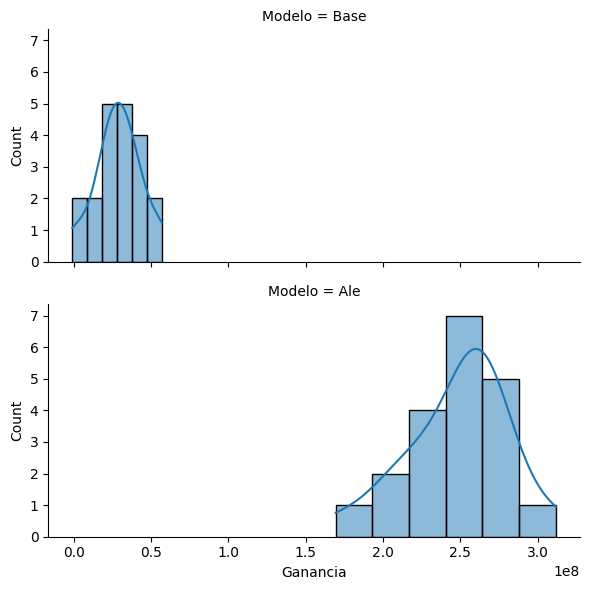

In [15]:
g = sns.FacetGrid(df_combined, row="Modelo", aspect=2)
g.map(sns.histplot, "Ganancia", kde=True)
plt.show()

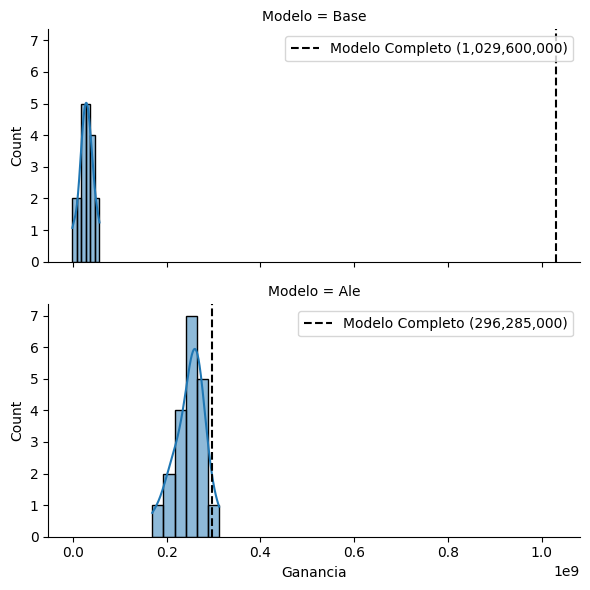

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Suponiendo que tienes definidos estos valores:
# ganancia_base = ...
# ganancia_ale = ...

valores_referencia = {
    'Base': ganancia_base,
    'Ale': ganancia_ale
}

g = sns.FacetGrid(df_combined, row="Modelo", aspect=2)
g.map(sns.histplot, "Ganancia", kde=True)

# Iterar sobre cada subplot y trazar su línea vertical correspondiente
for modelo, ax in g.axes_dict.items():
    valor = valores_referencia[modelo]
    ax.axvline(valor, color='black', linestyle='--', linewidth=1.5, label=f'Modelo Completo ({valor:,.0f})')
    ax.legend(loc='upper right')

plt.show()

* ¿Qué tan distintos son de los primero valores calculados con el modelo completo?
* ¿Con cuál se queda?
* ¿Por qué se produce semejante dispersión?
* ¿Cuál considera que es el "valor real"?

Podemos mirar la media

El modelo base, al permitir mayor depth y una menor cantidad de samples por hoja, se aprendió los datos del conjunto de entrenamiento mejor que el de Ale, pero fue incapaz de replicarlos en test (i.e. sobreajustó). El modelo de Ale obtuvo mayores ganancias en todas las particiones de test realizadads, por lo que nos resulta más adecuado. La dispersión observada obedece a: -El empleo de distintos sub-conjuntos de datos para entrenamiento/predicción -El empleo de distintos hiperparámetros. No estoy segura de a qué se refiere la pregunta sobre el "valor real"; si nos referimos a la ganancia que es capaz de proveer nuestro modelo, diría que ninguno, en clase dijimos que nos interesa la distribución

In [20]:
mean_base = df_combined[df_combined['Modelo'] == 'Base']['Ganancia'].mean()
mean_ale = df_combined[df_combined['Modelo'] == 'Ale']['Ganancia'].mean()

print(f"Ganancia media del modelo base:\t{mean_base/0.3:,.0f}")
print(f"Ganancia media del modelo ale:\t{mean_ale/0.3:,.0f}")

Ganancia media del modelo base:	96,647,222
Ganancia media del modelo ale:	827,902,778


In [21]:
mean_ale / mean_base

np.float64(8.566234587417009)

* Si no le gusta la media, ¿cómo más puede elegir entre dos modelos?

Podemos emplear otras medidas de tendencia central. Tb podríamos complementar con medidas de dispersión.
Dice Gemini:
Para comparar distribuciones de ganancias generadas por validación cruzada, las métricas más útiles cubren tendencia central, dispersión, riesgo (colas inferiores) y forma.

Métricas recomendadas para evaluar distribuciones de ganancia:
Mediana (median): Es más robusta que la media ante particiones atípicas (outliers).
Moda (mode): El valor que más se repite. En variables continuas suele haber pocos repetidos exactos; en ese caso conviene redondear antes (ej. x.round(-3).mode()) o fijarse en el pico del KDE del gráfico.
Desviación Estándar (std) y Rango Intercuartílico (IQR): Miden la estabilidad del modelo. Menor dispersión implica mayor consistencia entre particiones.
Percentiles Extremos ($Q_{05}$ y $Q_{25}$ / VaR): Permiten evaluar el riesgo financiero en el "peor de los casos" si el modelo tiene una partición desfavorable.
Asimetría (skew): Una asimetría positiva (right-skewed) indica mayor frecuencia de ganancias excepcionalmente altas, mientras que una negativa alerta sobre caídas abruptas de ganancia.
La curtosis mide la concentración de datos en el centro versus el grosor de las colas de la distribución en comparación con una distribución normal. En términos prácticos para evaluar modelos de Machine Learning y ganancias: mide la propensión a tener eventos atípicos o extremos (outliers). < 0 -> colas largas; > 0 -> pico en el centro

La forma más directa de calcularlas todas juntas por modelo en Pandas es usando groupby y agg:

In [22]:
import numpy as np

resumen = df_combined.groupby('Modelo')['Ganancia'].agg(
    Media='mean',
    Mediana='median',
    Moda=lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
    Desv_Std='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    Minimo='min',
    Q05=lambda x: x.quantile(0.05), # Percentil 5 (Peor escenario)
    Q95=lambda x: x.quantile(0.95), # Percentil 95 (Mejor escenario)
    Maximo='max',
    Asimetria='skew',
    Curtosis=lambda x: x.kurtosis()
).T

display(resumen)

Modelo,Ale,Base
Media,248370833.33,28994166.67
Mediana,257308333.33,28920833.33
Moda,169400000.00,-916666.67
Desv_Std,33055295.41,14897428.32
IQR,37560416.67,17095833.33
Minimo,169400000.00,-916666.67
Q05,199008333.33,1695833.33
Q95,288947083.33,55096250.00
Maximo,311850000.00,56925000.00
Asimetria,-0.60,-0.11


El modelo de Ale tiene mayor media, mediana y moda, lo que conlleva una clara mejora respecto del modelo base. Aunque presenta más dispersión (variabilidad entre particiones; que puede interpretarse como cierta inestabilidad en la capacidad de predicción), toda la distribución se concentra en valores mayores que los del modelo base, que incluso incurre en pérdidas en sus peores performances (i.e, las mínimas ganancias obtenidas son negativas).

Muy interesante, pero lo importante es que sucedería en el **futuro**. Por este motivo nos guardamos el mes de **Mayo**.

In [13]:
X_futuro = data[data['foto_mes'] == mes_test]
y_futuro = X_futuro['clase_ternaria']
X_futuro = X_futuro.drop(columns=['clase_ternaria'])

Sobre el mes de Mayo, **debemos usar el modelo que se entreno sobre todos los datos**

In [24]:
ganancia_mayo_base = ganancia(model_base, X_futuro, y_futuro)
ganancia_mayo_ale = ganancia(model_ale, X_futuro, y_futuro)

print(f"Ganancia de modelo Base en Abril:\t{ganancia_mayo_base:,.0f}")
print(f"Ganancia de modelo Ale en Abril:\t{ganancia_mayo_ale:,.0f}")


Ganancia de modelo Base en Abril:	1,017,500
Ganancia de modelo Ale en Abril:	191,152,500


* ¿Cuál es mejor?
* ¿Por qué cree que el mejor es el mejor?
* ¿Hubiera elegido sabiamente únicamente con los datos de **Febrero**?

El mundo es un lugar **cruel** para los data scientists. El escenario anterior tampoco es el presente para los alumnos. Ya que la primera competencia sigue el modelo **kaggle** que divide el dataset en una parte **pública** y otra **privada**. Simulemos los efectos que produce en la decisión del mejor modelo en los leaderboards, simulando varios a la vez.


De manera consistente con el análisis anterior, el modelo que mejor performa con datos nuevos es el de Ale. De nuevo, parece generalizar mejor y sobreajustar menos que el de base. Sin embargo, no sabemos a ciencia cierta si nuestros datos no ostentan cierta estacionalidad que haga que el recorte temporal de un único mes sea incapaz de iluminar lo que sucede en meses futuros, como sea el caso de febrero, mes de vacaciones y verano. 

In [ ]:
# podemos tomar más muestras, dado que solo vamos a scorear y eso es más rápido (pasamos los modelos ya entrenados a la función ganancia)
sss_futuro = StratifiedShuffleSplit(n_splits=50,
                             test_size=0.3,
                             random_state=semilla)

In [20]:
ganancias_futuro_privada_ale = []
ganancias_futuro_privada_base = []
ganancias_futuro_publica_ale = []
ganancias_futuro_publica_base = []

for train_index, test_index in sss_futuro.split(X_futuro, y_futuro):
  ganancias_futuro_privada_ale.append(ganancia(model_ale, X_futuro.iloc[train_index], y_futuro.iloc[train_index], prop=0.7))
  ganancias_futuro_privada_base.append(ganancia(model_base, X_futuro.iloc[train_index], y_futuro.iloc[train_index], prop=0.7))
  ganancias_futuro_publica_ale.append(ganancia(model_ale, X_futuro.iloc[test_index], y_futuro.iloc[test_index], prop=0.3))
  ganancias_futuro_publica_base.append(ganancia(model_base, X_futuro.iloc[test_index], y_futuro.iloc[test_index], prop=0.3))


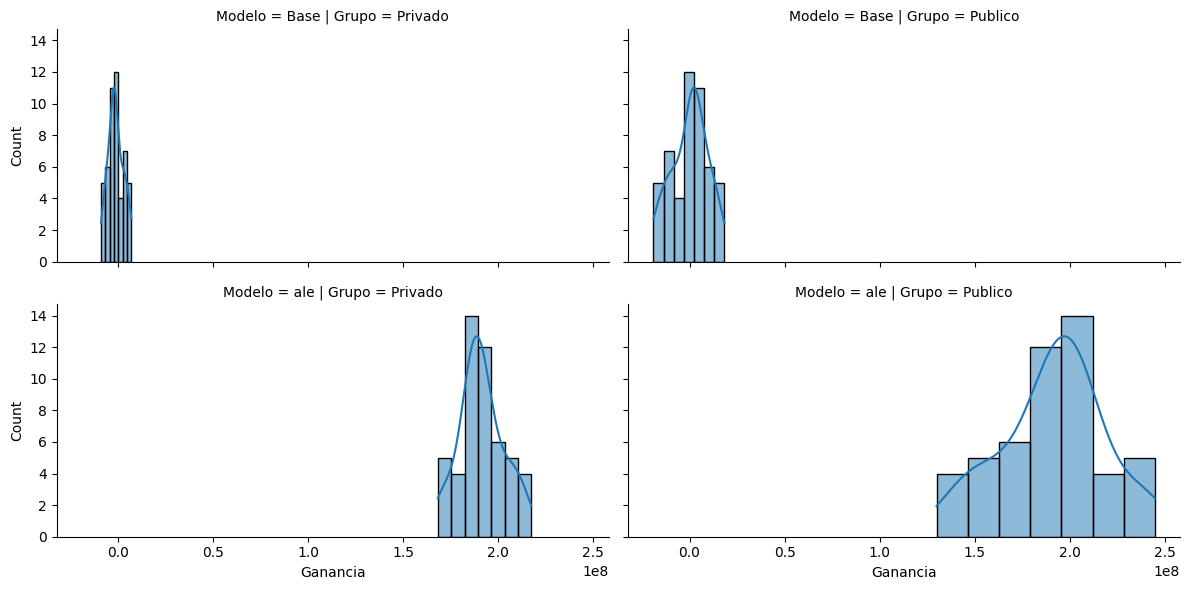

In [21]:
df_pred_1_ale = pd.DataFrame({'Ganancia': ganancias_futuro_privada_ale, 'Modelo': 'ale', 'Grupo': 'Privado'})
df_pred_2_ale = pd.DataFrame({'Ganancia': ganancias_futuro_publica_ale, 'Modelo': 'ale', 'Grupo': 'Publico'})
df_pred_1_base = pd.DataFrame({'Ganancia': ganancias_futuro_privada_base, 'Modelo': 'Base', 'Grupo': 'Privado'})
df_pred_2_base = pd.DataFrame({'Ganancia': ganancias_futuro_publica_base, 'Modelo': 'Base', 'Grupo': 'Publico'})

df_combined = pd.concat([df_pred_1_base, df_pred_2_base, df_pred_1_ale, df_pred_2_ale ])

g = sns.FacetGrid(df_combined, col="Grupo", row="Modelo", aspect=2)
g.map(sns.histplot, "Ganancia", kde=True)
plt.show()


In [27]:
mean_base_privado = df_combined[(df_combined['Modelo'] == 'Base') & (df_combined['Grupo'] == 'Privado')]['Ganancia'].mean()
mean_base_publico = df_combined[(df_combined['Modelo'] == 'Base') & (df_combined['Grupo'] == 'Publico')]['Ganancia'].mean()
mean_ale_privado = df_combined[(df_combined['Modelo'] == 'ale') & (df_combined['Grupo'] == 'Privado')]['Ganancia'].mean()
mean_ale_publico = df_combined[(df_combined['Modelo'] == 'ale') & (df_combined['Grupo'] == 'Publico')]['Ganancia'].mean()

print(f"Ganancia media del modelo base en privado: {mean_base_privado}")
print(f"Ganancia media del modelo base en publico: {mean_base_publico}")
print(f"Ganancia media del modelo ale en privado: {mean_ale_privado}")
print(f"Ganancia media del modelo ale en publico: {mean_ale_publico}")


Ganancia media del modelo base en privado: 817142.8571428572
Ganancia media del modelo base en publico: 1485000.0
Ganancia media del modelo ale en privado: 191194142.85714284
Ganancia media del modelo ale en publico: 191055333.33333337


* ¿Que significan estos resultados?

Dos cosas.

* El modelo ale, es un caso de **vagancia**. Cambiar 2 parámetros y esperar un cambio radical no es lo más inteligente que se puede hacer. Realmente hay que hacer un esfuerzo para separar las distribuciones.
* Elegir un modelo no es una tarea simple que se pueda hacer con una **certeza** absoluta.

Para encontrar buenos modelos una forma adecuada es la búsqueda de hiperparámetros. Podemos contar con las siguientes técnicas de búsqueda de hiperparámetros:

* **Grid Search**: Explora exhaustivamente todas las combinaciones posibles de hiperparámetros dentro de un conjunto predefinido de valores. Aunque es exhaustivo.

* **Random Search**: En lugar de probar todas las combinaciones posibles, selecciona un número aleatorio de combinaciones de hiperparámetros dentro de un rango predefinido.

* **Bayesian Optimization**: Este método construye un modelo probabilístico del rendimiento de los hiperparámetros y utiliza ese modelo para seleccionar los valores de hiperparámetros más prometedores.

* **Tree-structured Parzen Estimator (TPE)**: Una variante de la optimización bayesiana que utiliza estimadores de densidad basados en árboles (Parzen estimators) para modelar la probabilidad de los hiperparámetros óptimos. Es eficiente en la exploración de espacios de hiperparámetros complejos y se adapta bien a configuraciones con interdependencias entre los parámetros.

* **Genetic Algorithms**: Emplea principios de la evolución natural, como selección, cruce y mutación, para encontrar combinaciones óptimas de hiperparámetros. Es útil en espacios de búsqueda muy complejos, aunque puede ser computacionalmente costoso.

Todos son buenas opciones para la búsqueda de ... nah mentira, **grid search** apesta, si no me cree calcule el tiempo necesario para barrer el dominio de búsqueda.

Para la búsquedas de parámetros usaremos **Optuna**. **Optuna** es una librería poderosa y flexible, diseñada para realizar búsquedas eficientes y automatizadas.

* Utiliza casi todos los álgoritmos mencionados y más.

* Permite definir espacios de búsqueda complejos, incluyendo hiperparámetros categóricos, continuos, discretos y con dependencias condicionales.

* Ofrece un mecanismo de pruning o poda, que permite detener evaluaciones de configuraciones de hiperparámetros que no muestran promesas tempranas.

* Facilidad de Uso y Configuración.

* Proporciona herramientas de visualización integradas para analizar el progreso de la optimización, visualizar la importancia de los hiperparámetros y explorar las configuraciones probadas.

Buscaremos un mejor modelo de manera inteligente:

In [30]:

sss_opt = ShuffleSplit(n_splits=5, test_size=0.3, random_state=semilla)

def objective(trial, X, y, sss):
  # Limitaremos la busqueda a solo 3 hiperparámetros, pero puede poner los que quiera
  # criterion = trial.suggest_categorical('criterion', ['gini', 'entropy'])
  max_depth = trial.suggest_int('max_depth', 2, 20)
  min_samples_split = trial.suggest_int('min_samples_split', 2, 200)
  min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 20)
  # max_leaf_nodes = trial.suggest_int('max_leaf_nodes', 2, 20)

  def train_and_evaluate(train_index, test_index, X, y):
    m = DecisionTreeClassifier(
        # criterion=criterion,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        # max_leaf_nodes=max_leaf_nodes,
        random_state=semilla,
    )
    m.fit(X.iloc[train_index],y.iloc[train_index])
    ganancia_value = ganancia(m, X.iloc[test_index], y.iloc[test_index], prop=0.3)
    return ganancia_value

  results = Parallel(n_jobs=-1)(
      delayed(train_and_evaluate)(train_index, test_index, X, y)
      for train_index, test_index in sss.split(X)
  )

  return np.mean(results)

# Importante configurar la bbdd
#storage_name = "sqlite:////content/drive/MyDrive/DMEyF/2026/notebooks/data/optimization_tree.db"
storage_name = "sqlite:////Users/carof/Downloads/DENICOLAY/optimization_tree.db"  
study_name = "exp_101_decision-tree-opt"

study = optuna.create_study(
    direction="maximize",
    study_name=study_name,
    storage=storage_name,
    load_if_exists=True,
)

[I 2026-08-31 15:37:27,693] A new study created in RDB with name: exp_101_decision-tree-opt


Entre la muchas ventajas que tiene **Optuna** es que va almacenando las exploraciones en una base de datos, lo que nos permite continuar la búsqueda si esta se interrumpe.

In [31]:
# No quiero que se ejecute automaticamente, descomente y ejecute
#study.optimize(lambda trial: objective(trial, X, y, sss_opt), n_trials=100)

[I 2026-08-31 15:40:08,281] Trial 0 finished with value: 254668333.33333334 and parameters: {'max_depth': 10, 'min_samples_split': 187, 'min_samples_leaf': 4}. Best is trial 0 with value: 254668333.33333334.
[I 2026-08-31 15:40:26,992] Trial 1 finished with value: 240863333.33333334 and parameters: {'max_depth': 5, 'min_samples_split': 187, 'min_samples_leaf': 8}. Best is trial 0 with value: 254668333.33333334.
[I 2026-08-31 15:40:46,969] Trial 2 finished with value: 268583333.3333334 and parameters: {'max_depth': 6, 'min_samples_split': 146, 'min_samples_leaf': 15}. Best is trial 2 with value: 268583333.3333334.
[I 2026-08-31 15:41:13,468] Trial 3 finished with value: 214243333.3333333 and parameters: {'max_depth': 15, 'min_samples_split': 92, 'min_samples_leaf': 3}. Best is trial 2 with value: 268583333.3333334.
[I 2026-08-31 15:41:22,414] Trial 4 finished with value: 222328333.33333334 and parameters: {'max_depth': 2, 'min_samples_split': 11, 'min_samples_leaf': 4}. Best is trial 2 

PARA VOLVER A CORRER SI LO PARE

In [32]:
print(f"Trials completados: {len(study.trials)}")
print("Mejor ganancia hasta ahora:", study.best_value)
print("Mejores parámetros hasta ahora:", study.best_params)

Trials completados: 100
Mejor ganancia hasta ahora: 273863333.3333334
Mejores parámetros hasta ahora: {'max_depth': 6, 'min_samples_split': 196, 'min_samples_leaf': 5}


In [ ]:
# 1. Conectas al mismo storage y study (load_if_exists=True carga el progreso existente)
#study = optuna.create_study(
#    direction="maximize",
#    study_name=study_name,
#    storage=storage_name,
#    load_if_exists=True,
#)

# 2. Vuelves a lanzar optimize indicando la cantidad de trials NUEVOS que quieres sumar
#n_trials_pendientes = 50
#study.optimize(lambda trial: objective(trial, X, y, sss_opt), n_trials=n_trials_pendientes)

PARA CARGAR LO GUARDADO

In [4]:
import optuna
import optuna.visualization as optuna_vis

# Las mismas rutas que definiste antes
storage_name = "sqlite:////Users/carof/Downloads/DENICOLAY/optimization_tree.db"
study_name = "exp_101_decision-tree-opt"

# Cargar el estudio guardado desde la base de datos
study = optuna.load_study(
    study_name=study_name,
    storage=storage_name
)

# Verificar que cargó correctamente
print(f"Total de trials cargados: {len(study.trials)}")
print(f"Mejor ganancia: {study.best_value:,.2f}")
print("Mejores hiperparámetros:", study.best_params)
 

Total de trials cargados: 100
Mejor ganancia: 273,863,333.33
Mejores hiperparámetros: {'max_depth': 6, 'min_samples_split': 196, 'min_samples_leaf': 5}


A continuación veremos como fue el proceso de búsqueda a través de las visualizaciones que cuenta la herramienta (los gráficos son bastante autoexplicativos)

In [ ]:
#pip install plotly

In [5]:
optuna.visualization.plot_optimization_history(study)

In [6]:
plot_slice(study)

In [7]:
plot_contour(study)

In [8]:
plot_contour(study, params=["max_depth", "min_samples_leaf"])

* Observe los valles y las montañas en las distintas combinaciones de parámetros. ¿Seguiría explorando?
* Si una montaña esta cerca del máximo del intervalo que exploración de un hiperparámetro. ¿Qué recomienda hacer?
* Existe alguna relación intrinseca entre le `min_sample_leaf` y `min_sample_split`? Puede mejorar esta búsqueda conectando estos parámetros?

Pasemos a analizar como le fue al mejor modelo en **Mayo**

Max depth parece dar consistentemente mejor alrededor del 6, en cambio min sample split y leaf parecen mas dispersos. Si la montaña se acerca al maximo del intervalo, conviene alargar el rango de exploración para abarcar valores superiores. Min sample leaf y split están conceptualmente relacionados


La relación técnica entre ambos es jerárquica y condicional: min_samples_split actúa primero controlando si un nodo tiene el derecho de intentar dividirse, mientras que min_samples_leaf actúa como el filtro final que valida si esa división es permitida.⚙️ Definición técnica de cada unomin_samples_split: Es el número mínimo de muestras que debe tener un nodo interno para que el algoritmo intente buscar una división. Si el nodo tiene menos muestras que este valor, se convierte automáticamente en una hoja y no se divide.min_samples_leaf: Es el número mínimo de muestras que obligatoriamente deben quedar en cada uno de los nodos hijos (izquierdo y derecho) después de realizar una división. Si la división propuesta deja a cualquiera de las dos hojas con menos muestras de las especificadas, la división se descarta por completo.


En la práctica y por lógica de funcionamiento de los árboles de decisión, min_samples_leaf no debería ser mayor a min_samples_split, ya que configurarlo así anula el efecto de min_samples_split.

Para entender por qué ocurre esto:

min_samples_split: Es el número mínimo de muestras que debe tener un nodo padre para que el algoritmo si quiera intente dividirlo.

min_samples_leaf: Es el número mínimo de muestras que debe quedar en cada una de las ramas hijas tras la división para que dicho corte sea válido.

In [14]:
# Obtener el mejor modelo
best_trial = study.best_trial
best_model_params = best_trial.params
print("Mejor modelo:", best_model_params)

model_best = DecisionTreeClassifier(**best_model_params, random_state=semilla)
model_best.fit(X, y)

print(f"Ganancia del mejor modelo: {ganancia(model_best, X_futuro, y_futuro)}")

Mejor modelo: {'max_depth': 6, 'min_samples_split': 196, 'min_samples_leaf': 5}
Ganancia del mejor modelo: 212410000.0


Es mejor que los anteriores! y solo por una hora de procesamiento!!!

¿qué más podemos pedir por tan poco?

Veamos comparados con los anteriores que tanto mejor es...


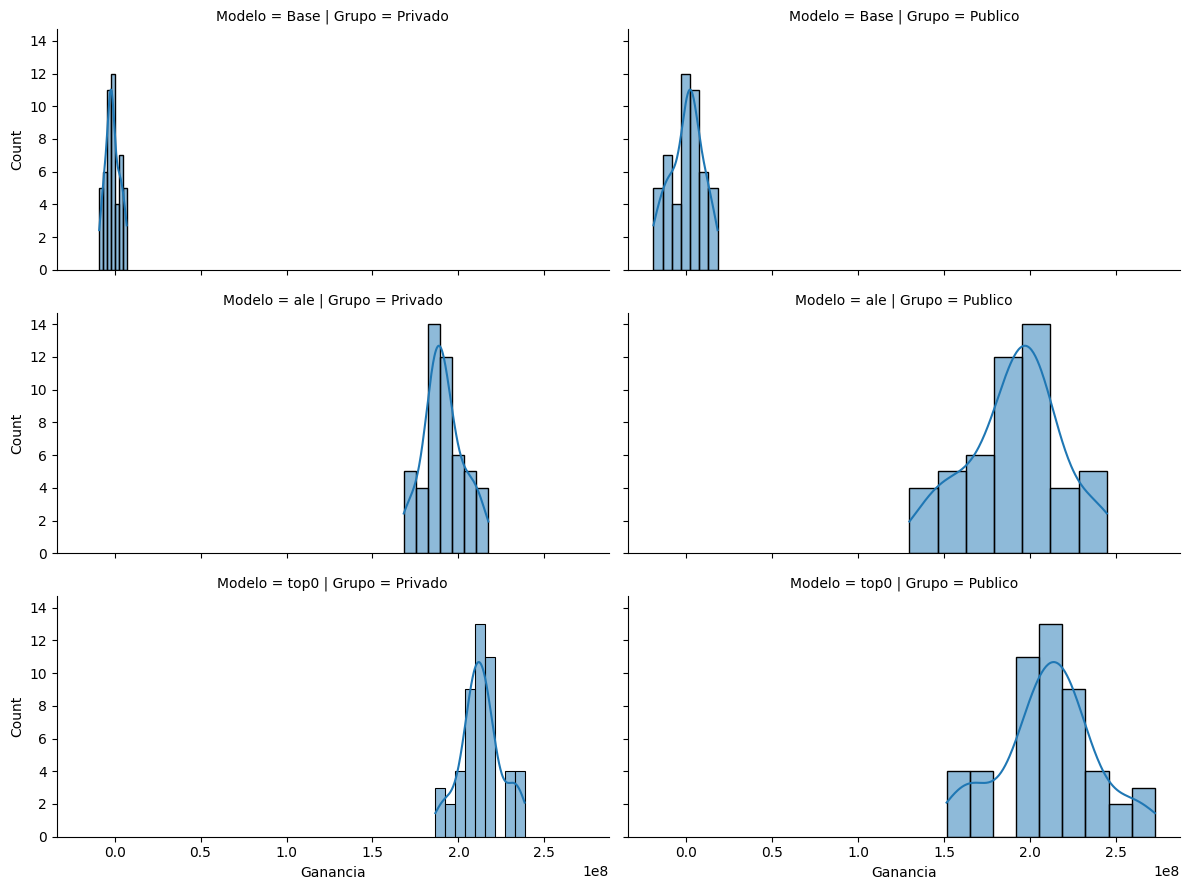

In [23]:
ganancias_futuro_top0_publica = []
ganancias_futuro_top0_privado = []
for train_index, test_index in sss_futuro.split(X_futuro, y_futuro):
  ganancias_futuro_top0_publica.append(ganancia(model_best, X_futuro.iloc[test_index], y_futuro.iloc[test_index], prop=0.3))
  ganancias_futuro_top0_privado.append(ganancia(model_best, X_futuro.iloc[train_index], y_futuro.iloc[train_index], prop=0.7))

df_pred_top0_privado = pd.DataFrame({'Ganancia': ganancias_futuro_top0_privado, 'Modelo': 'top0', 'Grupo': 'Privado'})
df_pred_top0_publica = pd.DataFrame({'Ganancia': ganancias_futuro_top0_publica, 'Modelo': 'top0', 'Grupo': 'Publico'})

df_combined = pd.concat([df_pred_1_base,
                         df_pred_2_base,
                         df_pred_1_ale,
                         df_pred_2_ale,
                         df_pred_top0_privado,
                         df_pred_top0_publica])

g = sns.FacetGrid(df_combined, col="Grupo", row="Modelo", aspect=2)
g.map(sns.histplot, "Ganancia", kde=True)
plt.show()

Bueno, no parece mucho mejor. Es tan solo mejor. Vamos moviendo de a poco la vara.

* ¿Qué se puede hacer para mejorarlo? Debate con la clase abierta


## Tarea:

* Ejecute todo de nuevo para su semilla y los hiperparámetros que considere.
* Ya tiene la búsqueda de Optuna. Duda existencial: Dado que no hay tanta distancia entre el primer modelo y los subsiguientes en optuna y que a su vez hicimos apenas 5 muestreos, no será posible que el mejor modelo en SSS no sea el mejor en el privado de **Mayo**?
    * Quédese con los top 5 de optuna. Use más muestras para cada modelo (20 o más)
    * Calcule la ganancia y su distribución en los conjuntos de validación
    * Cómo son las medias? ayudan a elegir el mejor modelo en el privado? con que confianza?
    * Sólo mirando la distribución del muestreo de validación, tiene herramientas para elegir el mejor modelo en el privado?
    * Puede pasar que comparando 2 modelos uno le gane al otro en el público, pero no así en el privado? En que porcentaje pasa?
         
Colaboración:
* Recuerde compartir con tus compañeros los nuevos scripts que hayas generado y las configuraciones que hayas probado por Zulip

Mejor modelo: {'max_depth': 6, 'min_samples_split': 196, 'min_samples_leaf': 5}
Ganancia del mejor modelo: 212410000.0

INTENTOS PREVIOS; NO CORRER

In [22]:
semilla = 42
sss_opt = ShuffleSplit(n_splits=5, test_size=0.3, random_state=semilla)

def objective(trial, X, y, sss):
  # Limitaremos la busqueda a solo 3 hiperparámetros, pero puede poner los que quiera
  # criterion = trial.suggest_categorical('criterion', ['gini', 'entropy'])
  max_depth = trial.suggest_int('max_depth', 2, 10)
  min_samples_split = trial.suggest_int('min_samples_split', 100, 200)
  min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)
  max_leaf_nodes = trial.suggest_int('max_leaf_nodes', 2, 20)

  def train_and_evaluate(train_index, test_index, X, y):
    m = DecisionTreeClassifier(
        # criterion=criterion,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_leaf_nodes=max_leaf_nodes,
        random_state=semilla,
    )
    m.fit(X.iloc[train_index],y.iloc[train_index])
    ganancia_value = ganancia(m, X.iloc[test_index], y.iloc[test_index], prop=0.3)
    return ganancia_value

  results = Parallel(n_jobs=-1)(
      delayed(train_and_evaluate)(train_index, test_index, X, y)
      for train_index, test_index in sss.split(X)
  )

  return np.mean(results)

# Importante configurar la bbdd
#storage_name = "sqlite:////content/drive/MyDrive/DMEyF/2026/notebooks/data/optimization_tree.db"
storage_name = "sqlite:////Users/carof/Downloads/DENICOLAY/optimization_tree.db"  
study_name = "exp_102_decision-tree-opt-vtarea"

study = optuna.create_study(
    direction="maximize",
    study_name=study_name,
    storage=storage_name,
    load_if_exists=True,
)

[I 2026-08-31 16:23:58,576] A new study created in RDB with name: exp_102_decision-tree-opt-vtarea


In [ ]:
def objective(trial, X, y, sss):
    max_depth = trial.suggest_int('max_depth', 2, 10)
    
    # 1. Sugiere primero el valor de split
    min_samples_split = trial.suggest_int('min_samples_split', 50, 200)
    
    # 2. Limita min_samples_leaf para que nunca supere min_samples_split // 2
    #    (o min_samples_split según tu criterio)
    max_leaf_limit = min(50, min_samples_split // 2)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, max_leaf_limit)
    
    max_leaf_nodes = trial.suggest_int('max_leaf_nodes', 2, 20)

    def train_and_evaluate(train_index, test_index, X, y):
        m = DecisionTreeClassifier(
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_leaf_nodes=max_leaf_nodes,
            random_state=semilla,
        )
        m.fit(X.iloc[train_index], y.iloc[train_index])
        ganancia_value = ganancia(m, X.iloc[test_index], y.iloc[test_index], prop=0.3)
        return ganancia_value

    results = Parallel(n_jobs=-1)(
        delayed(train_and_evaluate)(train_index, test_index, X, y)
        for train_index, test_index in sss.split(X)
    )

    return np.mean(results)

INTENTO FINAL DESP DE DIALOGAR CON GEMINI SOBRE LAS RELACIONES ENTRE MIS HIPERPARAMETROS

No tiene mucho sentido ejecutarlo exactamente como está, principalmente por dos motivos: incoherencia en los rangos de control de tamaño y redundancia que confunde al optimizador (TPE).Inconsistencias principales del código actualConflicto max_depth vs. max_leaf_nodes:Con max_depth hasta 10, un árbol completo podría alcanzar hasta $2^{10} = 1024$ hojas.Al limitar max_leaf_nodes a solo 20, estás capando severamente la capacidad del árbol sin importar qué tan profundo le permitas llegar. max_leaf_nodes=20 frena el árbol mucho antes de que explore profundidades reales de 8, 9 o 10.A la inversa, cuando Optuna elija max_depth = 2, el árbol tendrá un techo natural de 4 hojas, haciendo inútiles los valores de max_leaf_nodes entre 5 y 20 en ese trial.Desacople de escalas (split vs. leaf):min_samples_split está en un rango muy alto (100 a 200) mientras que min_samples_leaf está muy bajo (1 a 10).Aunque es matemáticamente válido ($100 \ge 2 \times 10$), min_samples_split está haciendo casi todo el trabajo restrictivo, dejando el efecto de min_samples_leaf en un segundo plano.Cómo conviene estructurarloPara optimizar árboles de decisión en Optuna, lo estándar es elegir una de dos estrategias:Estrategia A: Controlar por hojas y muestras (Recomendada)Deja que la forma del árbol sea asimétrica ("best-first") eliminando el límite rígido de profundidad y explorando un rango de hojas más amplio:

In [24]:
semilla = 42
sss_opt = ShuffleSplit(n_splits=5, test_size=0.3, random_state=semilla)

# def objective(trial, X, y, sss):
#     # Limitaremos la busqueda a solo 3 hiperparámetros, pero puede poner los que quiera
#     # criterion = trial.suggest_categorical('criterion', ['gini', 'entropy'])
#     # max_depth = trial.suggest_int('max_depth', 2, 10)
#     # min_samples_split = trial.suggest_int('min_samples_split', 100, 200)
#     # min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)
#     # max_leaf_nodes = trial.suggest_int('max_leaf_nodes', 2, 20)

def objective(trial, X, y, sss):
    # Dejar profundidad libre o muy alta
    max_depth = trial.suggest_int('max_depth', 4, 10)  # acotamos rango porque modelos anteriores dieron bien consistentemente en 6
    
    # Rango de hojas más amplio y realista
    max_leaf_nodes = trial.suggest_int('max_leaf_nodes', 10, 300, log=True)
    
    # Muestras proporcionales
    min_samples_split = trial.suggest_int('min_samples_split', 20, 500, log=True)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 5, min_samples_split // 2)

    def train_and_evaluate(train_index, test_index, X, y):
        m = DecisionTreeClassifier(
            # criterion=criterion,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_leaf_nodes=max_leaf_nodes,
            random_state=semilla,
        )
        m.fit(X.iloc[train_index], y.iloc[train_index])
        ganancia_value = ganancia(m, X.iloc[test_index], y.iloc[test_index], prop=0.3)
        return ganancia_value

    results = Parallel(n_jobs=-1)(
        delayed(train_and_evaluate)(train_index, test_index, X, y)
        for train_index, test_index in sss.split(X)
    )

    return np.mean(results)


# Importante configurar la bbdd
# storage_name = "sqlite:////content/drive/MyDrive/DMEyF/2026/notebooks/data/optimization_tree.db"
storage_name = "sqlite:////Users/carof/Downloads/DENICOLAY/optimization_tree.db"
study_name = "exp_102_decision-tree-opt-vtarea"

study = optuna.create_study(
    direction="maximize",
    study_name=study_name,
    storage=storage_name,
    load_if_exists=True,
)

[I 2026-08-31 18:53:01,451] Using an existing study with name 'exp_102_decision-tree-opt-vtarea' instead of creating a new one.


In [25]:
study.optimize(lambda trial: objective(trial, X, y, sss_opt), n_trials=100)

[I 2026-08-31 18:55:05,481] Trial 0 finished with value: 270801666.6666666 and parameters: {'max_depth': 6, 'max_leaf_nodes': 17, 'min_samples_split': 406, 'min_samples_leaf': 53}. Best is trial 0 with value: 270801666.6666666.
[I 2026-08-31 18:56:08,759] Trial 1 finished with value: 269976666.6666666 and parameters: {'max_depth': 5, 'max_leaf_nodes': 181, 'min_samples_split': 148, 'min_samples_leaf': 6}. Best is trial 0 with value: 270801666.6666666.
[I 2026-08-31 18:57:01,670] Trial 2 finished with value: 284771666.6666667 and parameters: {'max_depth': 9, 'max_leaf_nodes': 32, 'min_samples_split': 498, 'min_samples_leaf': 11}. Best is trial 2 with value: 284771666.6666667.
[I 2026-08-31 18:57:29,035] Trial 3 finished with value: 230120000.00000006 and parameters: {'max_depth': 10, 'max_leaf_nodes': 13, 'min_samples_split': 228, 'min_samples_leaf': 42}. Best is trial 2 with value: 284771666.6666667.
[I 2026-08-31 18:58:06,503] Trial 4 finished with value: 265686666.6666667 and paramet

Semilla es importante cuando hacemos pocas iteraciones
Si vemos que las cosas son muy parecidas, no probemos mucho mas 